# G4 Energy Deposition Histograms
Load and plot energy deposition (`fEdepInCyl_kev`) from 4 ROOT files

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import uproot

## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
})

In [66]:
def compton_edge(E_gamma):
    """
    Calculate Compton edge energy for a given gamma ray energy.
    E_compton = E_gamma / (1 + 2*E_gamma/m_e*c^2)
    where m_e*c^2 = 511 keV (electron rest mass energy)
    """
    m_e_c2 = 511.0  # keV
    return E_gamma*(1 -  1/ (1.0 + 2.0 * E_gamma / m_e_c2))
  
compton_edges = {
    'Co-57': compton_edge(122.1),  # keV
    'Cs-137': compton_edge(661.7),  # keV
}

print("Compton edges (keV):", compton_edges)

Compton edges (keV): {'Co-57': 39.482018008474576, 'Cs-137': 477.3734081988661}


In [67]:
# Define the ROOT files and their labels
root_files = {
    'Alpha (3V)': 'g4Data/alpha_base_vf_0d35_bare_3V.root',
    'Alpha Gas 2': 'g4Data/alphaGas2.root',
    # 'Gamma Co-57': 'g4Data/gammaCo57_base_LP_4d3V_h3d5.root',
    'Gamma Co-57': 'g4Data/liquidCo_1M.root',
    'Gamma Cs-137': 'g4Data/gammaCs137_base_LP_4d3V_h3d5.root',
}

# Load data from each file
data = {}
for label, filepath in root_files.items():
    with uproot.open(filepath) as file:
        tree = file['simOutput']
        edep = tree['fEdepInCyl_kev'].array(library='numpy')
        data[label] = edep
        print(f"{label:20s}: {len(edep):8d} events, mean={edep.mean():.2f} keV, max={edep.max():.2f} keV")

Alpha (3V)          :   781921 events, mean=3502.57 keV, max=4719.09 keV
Alpha Gas 2         :    78132 events, mean=2394.25 keV, max=4711.59 keV
Gamma Co-57         :   308920 events, mean=30.80 keV, max=692.40 keV
Gamma Cs-137        :   389214 events, mean=260.42 keV, max=661.00 keV


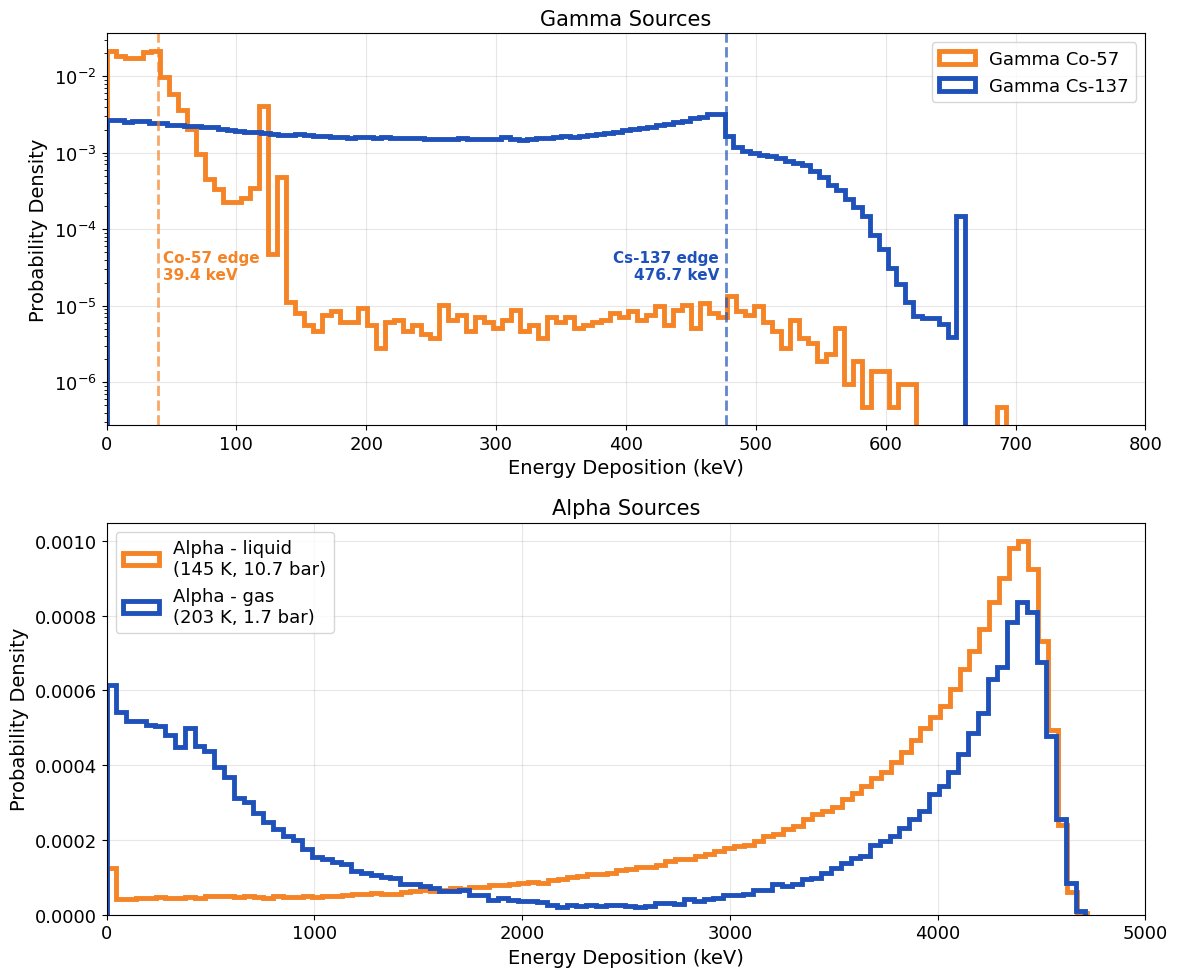

In [70]:
# Plot histograms in two stacked subplots: gamma sources (top), alpha sources (bottom)
gammaLog = True  # Toggle log scale on gamma plot

# New York Knicks colors
knicks_orange = '#F58426'
knicks_blue = '#1f51ba'

fig, (ax_gamma, ax_alpha) = plt.subplots(2, 1, figsize=(12, 10))

# Separate gamma and alpha sources
gamma_sources = ['Gamma Co-57', 'Gamma Cs-137']
alpha_sources = ['Alpha (3V)', 'Alpha Gas 2']
alpha_labels = ['Alpha - liquid\n(145 K, 10.7 bar)', 'Alpha - gas\n(203 K, 1.7 bar)']  # Fill in custom labels here

# ── Top plot: Gamma sources ────────────────────────────────────────
for label, color in zip(gamma_sources, [knicks_orange, knicks_blue]):
    if label in data:
        edep = data[label]
        ax_gamma.hist(edep, bins=100, histtype='step', linewidth=3.5, label=label, color=color, density=True)

# Add Compton edges for gamma sources
ce_co57 = compton_edge(122.0)
ce_cs137 = compton_edge(661.0)

ax_gamma.axvline(ce_co57, color=knicks_orange, linestyle='--', linewidth=2.0, alpha=0.7)
y_pos_co57 = ax_gamma.get_ylim()[1]*0.001 if gammaLog else ax_gamma.get_ylim()[1]*0.9
ax_gamma.text(ce_co57*1.1, y_pos_co57, f'Co-57 edge\n{ce_co57:.1f} keV', 
              fontsize=11, ha='left', color=knicks_orange, weight='bold')

ax_gamma.axvline(ce_cs137, color=knicks_blue, linestyle='--', linewidth=2.0, alpha=0.7)
y_pos_cs137 = ax_gamma.get_ylim()[1]*0.001 if gammaLog else ax_gamma.get_ylim()[1]*0.01
ax_gamma.text(ce_cs137-5, y_pos_cs137, f'Cs-137 edge\n{ce_cs137:.1f} keV', 
              fontsize=11, ha='right', color=knicks_blue, weight='bold')

ax_gamma.set_xlabel('Energy Deposition (keV)')
ax_gamma.set_ylabel('Probability Density')
ax_gamma.set_title('Gamma Sources')
ax_gamma.set_xlim(0, 800)
if gammaLog:
    ax_gamma.set_yscale('log')
ax_gamma.legend(loc='upper right')
ax_gamma.grid(True, alpha=0.3)

# ── Bottom plot: Alpha sources ────────────────────────────────────
for label, color, custom_label in zip(alpha_sources, [knicks_orange, knicks_blue], alpha_labels):
    if label in data:
        edep = data[label]
        plot_label = custom_label if custom_label else label
        ax_alpha.hist(edep, bins=100, histtype='step', linewidth=3.5, label=plot_label, color=color, density=True)

ax_alpha.set_xlabel('Energy Deposition (keV)')
ax_alpha.set_ylabel('Probability Density')
ax_alpha.set_title('Alpha Sources')
ax_alpha.set_xlim(0, 5000)
ax_alpha.legend(loc='upper left')
ax_alpha.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()